# CSCE 636 Project 1 — DNN for Estimating the m-Height

**Task.** Given `(n, k, m, P)`, predict the m-height of the code generated by `G = [I_k | P]`. All networks predict `z = log2(y)` and are trained with the MSE on `z`, which is the grading cost `(log2 y − log2 ŷ)²`.

**Submitted model files**
* `best_model.keras` — an ensemble of 3 residual MLPs, used for all `(k, m)` (Sections 3–5).
* `expert_k{k}_m{m}.keras` — one specialist network per `(k, m)`, trained with symmetry data augmentation (Section 7).
* `routing.json` — for each `(k, m)`, whether the prediction comes from the ensemble, the specialist, or the average of the two (Section 7c).

**Validation cost** (100,000 held-out samples): ensemble alone **0.609**; ensemble + specialists **0.594**.

**Packages.** Only TensorFlow/Keras, NumPy and Matplotlib are needed, and all are preinstalled in Google Colab.

## 1. Load the data and build the input vectors
Put `CSCE-636-Project-1-Train-n_k_m_P` and `CSCE-636-Project-1-Train-mHeights` in the working directory. Each sample becomes the 23-number vector `[n, k, m, P_0, …, P_19]`, where `P` is flattened and zero-padded to 20 numbers.

In [2]:
import pickle
import numpy as np

# Define file paths in the current Colab workspace
train_x_path = 'CSCE-636-Project-1-Train-n_k_m_P'
train_y_path = 'CSCE-636-Project-1-Train-mHeights'

# Load input features (raw_train_x)
with open(train_x_path, 'rb') as f:
    raw_train_x = pickle.load(f)

# Load target labels (raw_train_y)
with open(train_y_path, 'rb') as f:
    raw_train_y = pickle.load(f)

# Verify dataset size
print(f"Total training samples (X): {len(raw_train_x)}")
print(f"Total training labels (y): {len(raw_train_y)}")

# Display details of the first sample
sample_n, sample_k, sample_m, sample_P = raw_train_x[0]
print("\n--- Sample 0 Details ---")
print(f"n: {sample_n}")
print(f"k: {sample_k}")
print(f"m: {sample_m}")
print(f"P matrix shape: {sample_P.shape}")
print(f"P matrix content:\n{sample_P}")
print(f"Target m-height (y): {raw_train_y[0]}")


def preprocess_sample(sample, max_p_length=20):
    """
    Flattens matrix P, pads it with zeros to a uniform length of 20,
    and concatenates with [n, k, m] to create a fixed-size feature vector.
    """
    n, k, m, P = sample
    P_flat = P.flatten()

    # Pad zeros to ensure vector length matches maximum P size (k=4, n-k=5 -> 20 elements)
    padded_P = np.pad(P_flat, (0, max_p_length - len(P_flat)), mode='constant')

    # Combine features: [n, k, m, P_0, P_1, ..., P_19] -> total length = 23
    return np.concatenate(([n, k, m], padded_P))

# Convert raw data into formatted 2D NumPy arrays
X_train = np.array([preprocess_sample(s) for s in raw_train_x], dtype=np.float32)
y_train = np.array(raw_train_y, dtype=np.float32)

print("\n--- Processed Dataset Shapes ---")
print(f"X_train shape: {X_train.shape}")  # Output: (3833203, 23)
print(f"y_train shape: {y_train.shape}")  # Output: (3833203,)

Total training samples (X): 3833203
Total training labels (y): 3833203

--- Sample 0 Details ---
n: 9
k: 4
m: 4
P matrix shape: (4, 5)
P matrix content:
[[  7.  29.  32.  33. -42.]
 [ 24.  38.  -3.  26.  17.]
 [ 28. -35. -20.  32. -29.]
 [-32. -14.   1. -47. -18.]]
Target m-height (y): 415.96346010439976

--- Processed Dataset Shapes ---
X_train shape: (3833203, 23)
y_train shape: (3833203,)


## 2. Train / validation split and settings
* 100,000 random samples are held out for validation; the other 3,733,203 are used for training.
* Targets: `z = log2(y)`.

In [3]:
import os, time
import numpy as np
import keras
from keras import layers, optimizers

NUM_MODELS = 3          # ensemble size
EPOCHS = 40             # epochs per member
BATCH_SIZE = 1024
PEAK_LR = 0.0025
MEMBER_PATH = 'member_{}.keras'
FINAL_MODEL_PATH = 'best_model.keras'     # the submitted DNN (ensemble)

keras.mixed_precision.set_global_policy('mixed_float16')   # faster on the GPU; outputs stay float32

# Shuffle and split (same split as before)
np.random.seed(42)
indices = np.random.permutation(len(X_train))
x_val, partial_x_train = X_train[indices[:100000]], X_train[indices[100000:]]
y_val, partial_y_train = y_train[indices[:100000]], y_train[indices[100000:]]

# Targets in log2 space (the scale of the grading cost)
partial_z_train = np.log2(partial_y_train.astype(np.float64)).astype(np.float32)
z_val = np.log2(y_val.astype(np.float64)).astype(np.float32)

# Normalization statistics computed once with NumPy (much faster than Normalization.adapt on 3.7M rows)
feat_mean = partial_x_train.mean(axis=0, dtype=np.float64).astype(np.float32)
feat_var = partial_x_train.var(axis=0, dtype=np.float64).astype(np.float32)

# (k, m) group of every validation sample, for the per-group report
KM_LIST = [(4, 2), (4, 3), (4, 4), (4, 5), (5, 2), (5, 3), (5, 4), (6, 2), (6, 3)]
val_k, val_m = x_val[:, 1].astype(int), x_val[:, 2].astype(int)

def per_km_report(z_pred, title):
    cost = (np.clip(z_pred.reshape(-1).astype(np.float64), 0.0, 60.0) - z_val) ** 2
    print(f'{title}: overall validation cost = {cost.mean():.4f}')
    print('   ' + '  '.join(f'({k},{m}) {cost[(val_k == k) & (val_m == m)].mean():.3f}' for k, m in KM_LIST))
    return cost.mean()

print('train:', partial_x_train.shape, ' validation:', x_val.shape)

train: (3733203, 23)  validation: (100000, 23)


## 3. Network architecture
* `Normalization` standardizes the 23 inputs (mean and variance from the training set).
* **Structure branch:** `(n, k, m)` → Dense(256, ELU).
* **Matrix branch:** the 20 entries of `P` → Dense(1024) → Dense(1024) (ELU).
* The two branches are concatenated → Dense(2048) + BatchNorm + ELU → **3 residual blocks** (Dense-BN-ELU-Dense-BN, then skip connection and ELU) → Dense(512) → Dense(128) → Dense(1) = `ẑ = log2(ŷ)`.
* The output layer is kept in float32 for numerical accuracy under mixed precision.

In [ ]:
def build_member(name):
    inputs = keras.Input(shape=(23,))
    x = layers.Normalization(mean=feat_mean, variance=feat_var)(inputs)

    # Structure branch: (n, k, m)
    struct_feat = layers.Lambda(lambda t: t[:, :3])(x)
    struct_branch = layers.Dense(256, activation='elu')(struct_feat)

    # Matrix branch: flattened, zero-padded P
    p_feat = layers.Lambda(lambda t: t[:, 3:])(x)
    p_branch = layers.Dense(1024, activation='elu')(p_feat)
    p_branch = layers.Dense(1024, activation='elu')(p_branch)

    x = layers.Concatenate()([struct_branch, p_branch])
    x = layers.Dense(2048)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)

    # 3 residual blocks
    for _ in range(3):
        res = x
        x = layers.Dense(2048)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('elu')(x)
        x = layers.Dense(2048)(x)
        x = layers.BatchNormalization()(x)
        x = layers.add([x, res])
        x = layers.Activation('elu')(x)

    x = layers.Dense(512)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    outputs = layers.Dense(1, dtype='float32')(x)          # z_hat = log2(y_hat)
    return keras.Model(inputs, outputs, name=name)

## 4. Train the ensemble members
Each member uses a different random seed (different initialization and batch order), the MSE loss on `z`, AdamW (weight decay 1e-4), and a cosine-decay learning rate from 0.0025 down to 1e-5. `ModelCheckpoint` keeps the weights with the lowest validation MSE.

In [ ]:
histories = {}
for i in range(NUM_MODELS):
    path = MEMBER_PATH.format(i)
    if os.path.exists(path):
        print(f'member {i}: {path} already exists, skipping training')
        continue
    keras.utils.set_random_seed(100 + i)
    model = build_member(f'member_{i}')
    total_steps = (len(partial_x_train) // BATCH_SIZE) * EPOCHS
    lr_schedule = optimizers.schedules.CosineDecay(initial_learning_rate=PEAK_LR, decay_steps=total_steps,
                                                   alpha=1e-5 / PEAK_LR)
    model.compile(optimizer=optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4),
                  loss='mse', metrics=['mae'])
    t0 = time.time()
    histories[i] = model.fit(partial_x_train, partial_z_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                             validation_data=(x_val, z_val), verbose=2,
                             callbacks=[keras.callbacks.ModelCheckpoint(path, monitor='val_loss', save_best_only=True)])
    print(f'member {i} finished in {(time.time() - t0) / 60:.1f} min')
    del model

Epoch 1/40
3646/3646 - 97s - 27ms/step - loss: 1.6569 - mae: 0.7642 - val_loss: 0.8718 - val_mae: 0.6405
Epoch 2/40
3646/3646 - 40s - 11ms/step - loss: 0.7815 - mae: 0.5782 - val_loss: 0.7914 - val_mae: 0.6102
Epoch 3/40
3646/3646 - 40s - 11ms/step - loss: 0.7277 - mae: 0.5417 - val_loss: 0.7319 - val_mae: 0.5553
Epoch 4/40
3646/3646 - 39s - 11ms/step - loss: 0.7004 - mae: 0.5226 - val_loss: 0.7505 - val_mae: 0.5660
Epoch 5/40
3646/3646 - 39s - 11ms/step - loss: 0.6849 - mae: 0.5115 - val_loss: 0.7330 - val_mae: 0.5471
Epoch 6/40
3646/3646 - 41s - 11ms/step - loss: 0.6744 - mae: 0.5038 - val_loss: 0.7046 - val_mae: 0.5240
Epoch 7/40
3646/3646 - 40s - 11ms/step - loss: 0.6668 - mae: 0.4982 - val_loss: 0.6853 - val_mae: 0.5057
Epoch 8/40
3646/3646 - 40s - 11ms/step - loss: 0.6609 - mae: 0.4939 - val_loss: 0.6765 - val_mae: 0.4979
Epoch 9/40
3646/3646 - 40s - 11ms/step - loss: 0.6560 - mae: 0.4905 - val_loss: 0.6719 - val_mae: 0.4936
Epoch 10/40
3646/3646 - 40s - 11ms/step - loss: 0.6516 

## 5. Build and save the ensemble (the submitted DNN)
The best checkpoint of every member is loaded and the members are combined into **one Keras model**. The input goes to all members, and an `Average` layer averages their `ẑ`. The ensemble is saved as `best_model.keras`. The validation cost is printed for each member and for the ensemble, overall and per `(k, m)`.

In [ ]:
members = [keras.models.load_model(MEMBER_PATH.format(i), safe_mode=False) for i in range(NUM_MODELS)]
for i, mem in enumerate(members):
    per_km_report(mem.predict(x_val, batch_size=4096, verbose=0), f'member {i}')

ens_in = keras.Input(shape=(23,))
ens_out = layers.Average(dtype='float32')([mem(ens_in) for mem in members])
ensemble = keras.Model(ens_in, ens_out, name='m_height_ensemble')
ensemble.save(FINAL_MODEL_PATH)

best_model = keras.models.load_model(FINAL_MODEL_PATH, safe_mode=False)
z_val_pred = best_model.predict(x_val, batch_size=4096, verbose=0).reshape(-1)
per_km_report(z_val_pred, 'ENSEMBLE')

y_val_pred = np.power(2.0, np.clip(z_val_pred.astype(np.float64), 0.0, 60.0))
for i in range(5):
    print(f'Sample {i} | True y: {y_val[i]:.4f} | Predicted y: {y_val_pred[i]:.4f}')

member 0: overall validation cost = 0.6186
   (4,2) 0.055  (4,3) 0.092  (4,4) 0.306  (4,5) 2.142  (5,2) 0.063  (5,3) 0.282  (5,4) 2.225  (6,2) 0.140  (6,3) 1.821
member 1: overall validation cost = 0.6199
   (4,2) 0.054  (4,3) 0.092  (4,4) 0.305  (4,5) 2.155  (5,2) 0.061  (5,3) 0.282  (5,4) 2.229  (6,2) 0.135  (6,3) 1.825
member 2: overall validation cost = 0.6218
   (4,2) 0.054  (4,3) 0.091  (4,4) 0.305  (4,5) 2.141  (5,2) 0.062  (5,3) 0.280  (5,4) 2.258  (6,2) 0.137  (6,3) 1.861
ENSEMBLE: overall validation cost = 0.6093
   (4,2) 0.052  (4,3) 0.089  (4,4) 0.297  (4,5) 2.129  (5,2) 0.059  (5,3) 0.271  (5,4) 2.204  (6,2) 0.130  (6,3) 1.785
Sample 0 | True y: 51.6752 | Predicted y: 70.0980
Sample 1 | True y: 1272.9608 | Predicted y: 1077.0563
Sample 2 | True y: 135.3006 | Predicted y: 137.2093
Sample 3 | True y: 269.5912 | Predicted y: 296.2490
Sample 4 | True y: 2468.6343 | Predicted y: 2316.0630


### Validation results of the ensemble (per `(k, m)`)

| (k, m) | (4,2) | (4,3) | (4,4) | (4,5) | (5,2) | (5,3) | (5,4) | (6,2) | (6,3) | overall |
|---|---|---|---|---|---|---|---|---|---|---|
| member 0 | 0.055 | 0.092 | 0.306 | 2.142 | 0.063 | 0.282 | 2.225 | 0.140 | 1.821 | 0.6186 |
| member 1 | 0.054 | 0.092 | 0.305 | 2.155 | 0.061 | 0.282 | 2.229 | 0.135 | 1.825 | 0.6199 |
| member 2 | 0.054 | 0.091 | 0.305 | 2.141 | 0.062 | 0.280 | 2.258 | 0.137 | 1.861 | 0.6218 |
| **ensemble** | **0.052** | **0.089** | **0.297** | **2.129** | **0.059** | **0.271** | **2.204** | **0.130** | **1.785** | **0.6093** |

Averaging the 3 members lowers the cost for every `(k, m)`. The three groups with `m = n − k`, that is `(4,5)`, `(5,4)` and `(6,3)`, are much harder than the others.

## 6. Training curves of the ensemble members

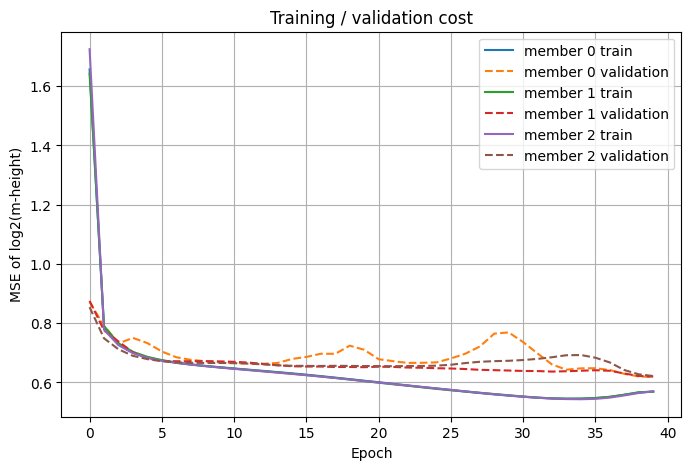

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
for i, h in histories.items():
    plt.plot(h.history['loss'], label=f'member {i} train')
    plt.plot(h.history['val_loss'], '--', label=f'member {i} validation')
plt.xlabel('Epoch'); plt.ylabel('MSE of log2(m-height)'); plt.title('Training / validation cost')
plt.grid(True); plt.legend(); plt.show()

## 7. Specialist networks

For each `(k, m)`, a separate network is trained on that group only. Its input is the flattened `P` of that group (`k·(n−k)` numbers, no padding), standardized by a `Normalization` layer. It goes through Dense(1024) + BatchNorm + ELU, then 3 residual blocks of width 1024, then Dense(256, ELU), then Dense(1). 5% of the group's training samples are held out to choose the best epoch. Training uses the MSE loss, AdamW and a cosine learning-rate schedule.

* **7a** loads the ensemble.
* **7b** trains specialists for `(6,2)`, `(5,2)` and `(4,2)` without augmentation. These over-fitted (for `(6,2)`: training 0.03, held-out 0.13) and were replaced by 7b-3.
* **7b-2** is a first test of data augmentation on `(6,2)`.
* **7b-3** trains the final specialists, with augmentation, for all nine groups.
* **7c** chooses, for each group, the ensemble, the specialist, or their average, whichever has the lowest validation cost, and writes the choice to `routing.json`.

In [4]:
# 7a. Setup: Google Drive backup folder, and the v3 ensemble
import os, json, shutil,keras
from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/CSCE636_project1'
os.makedirs(DRIVE_DIR, exist_ok=True)
if not os.path.exists('best_model.keras'):
    shutil.copy(os.path.join(DRIVE_DIR, 'best_model_v3.keras'), 'best_model.keras')
keras.config.enable_unsafe_deserialization()

main_model = keras.models.load_model('best_model.keras', safe_mode=False)
z_val_main = main_model.predict(x_val, batch_size=4096, verbose=0).reshape(-1).astype(np.float64)
per_km_report(z_val_main, 'v3 ensemble (best_model.keras)')

Mounted at /content/drive
v3 ensemble (best_model.keras): overall validation cost = 0.6093
   (4,2) 0.052  (4,3) 0.089  (4,4) 0.297  (4,5) 2.129  (5,2) 0.059  (5,3) 0.271  (5,4) 2.204  (6,2) 0.130  (6,3) 1.785


np.float64(0.6093307942610189)

In [5]:
# 7b. Train one specialist network per group
EXPERT_GROUPS = [(6, 2), (5, 2), (4, 2)]
EXPERT_EPOCHS = {(6, 2): 250, (5, 2): 60, (4, 2): 60}
EXPERT_LR = 0.002
EXPERT_PATH = 'expert_k{}_m{}.keras'
tr_k, tr_m = partial_x_train[:, 1].astype(int), partial_x_train[:, 2].astype(int)

def build_expert(dim, mean, var, name, width=1024, blocks=3):
    inp = keras.Input(shape=(dim,))
    x = layers.Normalization(mean=mean, variance=var)(inp)
    x = layers.Dense(width)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    for _ in range(blocks):
        res = x
        x = layers.Dense(width)(x); x = layers.BatchNormalization()(x); x = layers.Activation('elu')(x)
        x = layers.Dense(width)(x); x = layers.BatchNormalization()(x)
        x = layers.Activation('elu')(layers.add([x, res]))
    x = layers.Dense(256, activation='elu')(x)
    out = layers.Dense(1, dtype='float32')(x)            # z_hat = log2(y_hat)
    return keras.Model(inp, out, name=name)

expert_histories = {}
for k, m in EXPERT_GROUPS:
    path, dim = EXPERT_PATH.format(k, m), k * (9 - k)
    if os.path.exists(path):
        print(f'({k},{m}): {path} already exists, skipping'); continue
    if os.path.exists(os.path.join(DRIVE_DIR, path)):
        shutil.copy(os.path.join(DRIVE_DIR, path), path)
        print(f'({k},{m}): restored {path} from Drive, skipping'); continue
    idx = np.where((tr_k == k) & (tr_m == m))[0]
    Xg, zg = partial_x_train[idx, 3:3 + dim], partial_z_train[idx]
    n_ck = len(idx) // 20                                   # 5% to pick the best epoch
    X_fit, z_fit, X_ck, z_ck = Xg[n_ck:], zg[n_ck:], Xg[:n_ck], zg[:n_ck]
    keras.utils.set_random_seed(300 + 10 * k + m)
    model = build_expert(dim, X_fit.mean(0), X_fit.var(0), f'expert_k{k}_m{m}')
    steps = (len(X_fit) // BATCH_SIZE) * EXPERT_EPOCHS[(k, m)]
    model.compile(optimizer=optimizers.AdamW(
                      learning_rate=optimizers.schedules.CosineDecay(EXPERT_LR, steps, alpha=1e-5 / EXPERT_LR),
                      weight_decay=1e-4, clipnorm=1.0),
                  loss='mse')
    tmp = path.replace('.keras', '.partial.keras')
    t0 = time.time()
    expert_histories[(k, m)] = model.fit(
        X_fit, z_fit, epochs=EXPERT_EPOCHS[(k, m)], batch_size=BATCH_SIZE, validation_data=(X_ck, z_ck), verbose=2,
        callbacks=[keras.callbacks.ModelCheckpoint(tmp, monitor='val_loss', save_best_only=True)])
    os.replace(tmp, path)
    shutil.copy(path, DRIVE_DIR)                            # backup
    print(f'({k},{m}): {len(X_fit)} training samples, finished in {(time.time() - t0) / 60:.1f} min')

(6,2): restored expert_k6_m2.keras from Drive, skipping
(5,2): restored expert_k5_m2.keras from Drive, skipping
(4,2): restored expert_k4_m2.keras from Drive, skipping


In [6]:
# NOTE: first augmentation experiment, kept for documentation. It was superseded by 7b-3, which retrained (6,2)
#       for 60 epochs. Do NOT re-run this cell: it deletes expert_k6_m2.keras before retraining.
# 7b-2. (6,2) specialist trained with symmetry augmentation (row/column permutations and sign flips of P;
#        these leave the m-height unchanged, see the project's definition). Training data only.
k, m = 6, 2
r, dim = 9 - k, k * (9 - k)
path = EXPERT_PATH.format(k, m)
for p in [path, os.path.join(DRIVE_DIR, path)]:
    if os.path.exists(p): os.remove(p)

def augment(P, copies, rng):
    out = [P]
    for _ in range(copies - 1):
        Q = np.take_along_axis(P, np.argsort(rng.random((len(P), k)), 1)[:, :, None], 1)    # row permutation
        Q = np.take_along_axis(Q, np.argsort(rng.random((len(P), r)), 1)[:, None, :], 2)    # column permutation
        Q = Q * rng.choice([-1.0, 1.0], (len(P), k, 1)) * rng.choice([-1.0, 1.0], (len(P), 1, r))  # signs
        out.append(Q)
    return np.concatenate(out)

idx = np.where((tr_k == k) & (tr_m == m))[0]
Xg, zg = partial_x_train[idx, 3:3 + dim], partial_z_train[idx]
n_ck = len(idx) // 20
X_ck, z_ck = Xg[:n_ck], zg[:n_ck]                                   # held-out 5%, not augmented
COPIES, AUG_EPOCHS = 10, 30
rng = np.random.default_rng(0)
X_fit = augment(Xg[n_ck:].reshape(-1, k, r), COPIES, rng).reshape(-1, dim).astype(np.float32)
z_fit = np.tile(zg[n_ck:], COPIES)
print('augmented training set:', X_fit.shape)

keras.utils.set_random_seed(362)
model = build_expert(dim, X_fit.mean(0), X_fit.var(0), f'expert_k{k}_m{m}')
steps = (len(X_fit) // BATCH_SIZE) * AUG_EPOCHS
model.compile(optimizer=optimizers.AdamW(
                  learning_rate=optimizers.schedules.CosineDecay(EXPERT_LR, steps, alpha=1e-5 / EXPERT_LR),
                  weight_decay=1e-4, clipnorm=1.0), loss='mse')
tmp = path.replace('.keras', '.partial.keras')
t0 = time.time()
expert_histories = {(k, m): model.fit(X_fit, z_fit, epochs=AUG_EPOCHS, batch_size=BATCH_SIZE, shuffle=True,
                                      validation_data=(X_ck, z_ck), verbose=2,
                                      callbacks=[keras.callbacks.ModelCheckpoint(tmp, monitor='val_loss', save_best_only=True)])}
os.replace(tmp, path); shutil.copy(path, DRIVE_DIR)
print(f'finished in {(time.time() - t0) / 60:.1f} min')

augmented training set: (2332700, 18)
Epoch 1/30
2279/2279 - 38s - 17ms/step - loss: 1.1766 - val_loss: 0.4773
Epoch 2/30
2279/2279 - 8s - 4ms/step - loss: 0.4660 - val_loss: 0.3963
Epoch 3/30
2279/2279 - 8s - 3ms/step - loss: 0.3893 - val_loss: 0.2894
Epoch 4/30
2279/2279 - 8s - 3ms/step - loss: 0.3214 - val_loss: 0.2358
Epoch 5/30
2279/2279 - 8s - 3ms/step - loss: 0.2463 - val_loss: 0.1612
Epoch 6/30
2279/2279 - 7s - 3ms/step - loss: 0.2084 - val_loss: 0.1651
Epoch 7/30
2279/2279 - 8s - 3ms/step - loss: 0.1849 - val_loss: 0.1329
Epoch 8/30
2279/2279 - 8s - 4ms/step - loss: 0.1687 - val_loss: 0.1095
Epoch 9/30
2279/2279 - 8s - 3ms/step - loss: 0.1551 - val_loss: 0.0977
Epoch 10/30
2279/2279 - 8s - 3ms/step - loss: 0.1453 - val_loss: 0.0892
Epoch 11/30
2279/2279 - 8s - 3ms/step - loss: 0.1346 - val_loss: 0.0859
Epoch 12/30
2279/2279 - 8s - 3ms/step - loss: 0.1264 - val_loss: 0.0859
Epoch 13/30
2279/2279 - 8s - 4ms/step - loss: 0.1191 - val_loss: 0.0767
Epoch 14/30
2279/2279 - 7s - 3ms/

### 7b-3. Specialists with symmetry data augmentation

Permuting the rows or columns of `P`, or flipping the sign of a row or column, gives an equivalent code: its codewords are only permuted or have some coordinates negated. So the m-height is exactly unchanged. For each group, every training matrix is copied 5–10 times with random permutations and sign flips, and every copy keeps the same label. This is used for training only; at prediction time `P` is fed to the network unchanged.

In [7]:
# 7b-3. Specialists with symmetry data augmentation for all groups (training only).
#        A group is skipped once its augmented specialist is finished (marker file *.aug_done).
AUG_SETTINGS = {                 # (k, m): (augmented copies, epochs); easy groups first, hard ones last
    (5, 2): (10, 30), (4, 2): (5, 30), (4, 3): (5, 30), (5, 3): (10, 30), (4, 4): (5, 30),
    (6, 2): (10, 60), (6, 3): (10, 30), (5, 4): (10, 30), (4, 5): (5, 30)}

def augment_group(P, copies, rng):
    n_, kk, rr = P.shape
    out = [P]
    for _ in range(copies - 1):
        Q = np.take_along_axis(P, np.argsort(rng.random((n_, kk)), 1)[:, :, None], 1)   # row permutation
        Q = np.take_along_axis(Q, np.argsort(rng.random((n_, rr)), 1)[:, None, :], 2)   # column permutation
        Q = Q * rng.choice([-1.0, 1.0], (n_, kk, 1)) * rng.choice([-1.0, 1.0], (n_, 1, rr))  # sign flips
        out.append(Q)
    return np.concatenate(out)

expert_histories = {}
for (k, m), (copies, n_epochs) in AUG_SETTINGS.items():
    r, dim = 9 - k, k * (9 - k)
    path = EXPERT_PATH.format(k, m); marker = path + '.aug_done'
    if os.path.exists(os.path.join(DRIVE_DIR, marker)) and not os.path.exists(marker):
        for f in (path, marker): shutil.copy(os.path.join(DRIVE_DIR, f), f)
    if os.path.exists(marker):
        print(f'({k},{m}): augmented specialist already trained, skipping'); continue
    idx = np.where((tr_k == k) & (tr_m == m))[0]
    Xg, zg = partial_x_train[idx, 3:3 + dim], partial_z_train[idx]
    n_ck = len(idx) // 20
    X_ck, z_ck = Xg[:n_ck], zg[:n_ck]                               # held-out 5%, not augmented
    rng = np.random.default_rng(10 * k + m)
    X_fit = augment_group(Xg[n_ck:].reshape(-1, k, r), copies, rng).reshape(-1, dim).astype(np.float32)
    z_fit = np.tile(zg[n_ck:], copies)
    keras.utils.set_random_seed(400 + 10 * k + m)
    model = build_expert(dim, X_fit.mean(0), X_fit.var(0), f'expert_k{k}_m{m}')
    steps = (len(X_fit) // BATCH_SIZE) * n_epochs
    model.compile(optimizer=optimizers.AdamW(
                      learning_rate=optimizers.schedules.CosineDecay(EXPERT_LR, steps, alpha=1e-5 / EXPERT_LR),
                      weight_decay=1e-4, clipnorm=1.0), loss='mse')
    tmp = path.replace('.keras', '.partial.keras')
    t0 = time.time()
    expert_histories[(k, m)] = model.fit(
        X_fit, z_fit, epochs=n_epochs, batch_size=BATCH_SIZE, shuffle=True, validation_data=(X_ck, z_ck), verbose=2,
        callbacks=[keras.callbacks.ModelCheckpoint(tmp, monitor='val_loss', save_best_only=True)])
    os.replace(tmp, path)
    open(marker, 'w').close()
    hist_file = path + '.history.json'
    json.dump({key: [float(v) for v in vals] for key, vals in expert_histories[(k, m)].history.items()}, open(hist_file, 'w'))
    shutil.copy(hist_file, DRIVE_DIR)
    for f in (path, marker): shutil.copy(f, DRIVE_DIR)              # backup
    print(f'({k},{m}): {len(X_fit):,} augmented samples, finished in {(time.time() - t0) / 60:.1f} min')
    del X_fit, z_fit, model

(5,2): augmented specialist already trained, skipping
Epoch 1/30
3045/3045 - 33s - 11ms/step - loss: 1.3295 - val_loss: 0.1240
Epoch 2/30
3045/3045 - 11s - 4ms/step - loss: 0.2440 - val_loss: 0.1169
Epoch 3/30
3045/3045 - 11s - 4ms/step - loss: 0.2015 - val_loss: 0.0844
Epoch 4/30
3045/3045 - 10s - 3ms/step - loss: 0.1764 - val_loss: 0.0928
Epoch 5/30
3045/3045 - 11s - 4ms/step - loss: 0.1589 - val_loss: 0.0739
Epoch 6/30
3045/3045 - 10s - 3ms/step - loss: 0.1460 - val_loss: 0.0862
Epoch 7/30
3045/3045 - 10s - 3ms/step - loss: 0.1359 - val_loss: 0.0778
Epoch 8/30
3045/3045 - 11s - 3ms/step - loss: 0.1263 - val_loss: 0.0719
Epoch 9/30
3045/3045 - 11s - 4ms/step - loss: 0.1177 - val_loss: 0.0715
Epoch 10/30
3045/3045 - 11s - 4ms/step - loss: 0.1117 - val_loss: 0.0604
Epoch 11/30
3045/3045 - 11s - 3ms/step - loss: 0.1052 - val_loss: 0.0591
Epoch 12/30
3045/3045 - 11s - 3ms/step - loss: 0.0994 - val_loss: 0.0586
Epoch 13/30
3045/3045 - 11s - 3ms/step - loss: 0.0946 - val_loss: 0.0582
Epoch

### 7b-4. Re-training `(5,2)`
The training history of `(5,2)` from 7b-3 was lost when the Colab session was reset. This cell re-trains it with the same settings in order to record its curve. This model is the submitted `expert_k5_m2.keras`.

In [11]:
# 7b-4. Re-train the (5,2) augmented specialist with the same settings as 7b-3, so that its training
#        history is recorded (the first run finished in an earlier session, before history saving was added).
k, m = 5, 2
copies, n_epochs = AUG_SETTINGS[(k, m)]
r, dim = 9 - k, k * (9 - k)
path = EXPERT_PATH.format(k, m); marker = path + '.aug_done'
idx = np.where((tr_k == k) & (tr_m == m))[0]
Xg, zg = partial_x_train[idx, 3:3 + dim], partial_z_train[idx]
n_ck = len(idx) // 20
X_ck, z_ck = Xg[:n_ck], zg[:n_ck]                               # held-out 5%, not augmented
rng = np.random.default_rng(10 * k + m)
X_fit = augment_group(Xg[n_ck:].reshape(-1, k, r), copies, rng).reshape(-1, dim).astype(np.float32)
z_fit = np.tile(zg[n_ck:], copies)
keras.utils.set_random_seed(400 + 10 * k + m)
model = build_expert(dim, X_fit.mean(0), X_fit.var(0), f'expert_k{k}_m{m}')
steps = (len(X_fit) // BATCH_SIZE) * n_epochs
model.compile(optimizer=optimizers.AdamW(
                  learning_rate=optimizers.schedules.CosineDecay(EXPERT_LR, steps, alpha=1e-5 / EXPERT_LR),
                  weight_decay=1e-4, clipnorm=1.0), loss='mse')
tmp = path.replace('.keras', '.partial.keras')
t0 = time.time()
h = model.fit(X_fit, z_fit, epochs=n_epochs, batch_size=BATCH_SIZE, shuffle=True, validation_data=(X_ck, z_ck),
              verbose=2, callbacks=[keras.callbacks.ModelCheckpoint(tmp, monitor='val_loss', save_best_only=True)])
os.replace(tmp, path)
open(marker, 'w').close()
hist_file = path + '.history.json'
json.dump({key: [float(v) for v in vals] for key, vals in h.history.items()}, open(hist_file, 'w'))
for f in (path, marker, hist_file): shutil.copy(f, DRIVE_DIR)   # backup
print(f'({k},{m}): {len(X_fit):,} augmented samples, finished in {(time.time() - t0) / 60:.1f} min')
del X_fit, z_fit, model

Epoch 1/30
3088/3088 - 32s - 10ms/step - loss: 1.2600 - val_loss: 0.1562
Epoch 2/30
3088/3088 - 11s - 4ms/step - loss: 0.2165 - val_loss: 0.1433
Epoch 3/30
3088/3088 - 11s - 4ms/step - loss: 0.1932 - val_loss: 0.1053
Epoch 4/30
3088/3088 - 11s - 4ms/step - loss: 0.1773 - val_loss: 0.0943
Epoch 5/30
3088/3088 - 11s - 4ms/step - loss: 0.1656 - val_loss: 0.0854
Epoch 6/30
3088/3088 - 11s - 4ms/step - loss: 0.1551 - val_loss: 0.0817
Epoch 7/30
3088/3088 - 11s - 4ms/step - loss: 0.1451 - val_loss: 0.0753
Epoch 8/30
3088/3088 - 11s - 4ms/step - loss: 0.1370 - val_loss: 0.0696
Epoch 9/30
3088/3088 - 11s - 4ms/step - loss: 0.1279 - val_loss: 0.0663
Epoch 10/30
3088/3088 - 11s - 4ms/step - loss: 0.1201 - val_loss: 0.0652
Epoch 11/30
3088/3088 - 11s - 4ms/step - loss: 0.1142 - val_loss: 0.0644
Epoch 12/30
3088/3088 - 11s - 4ms/step - loss: 0.1077 - val_loss: 0.0617
Epoch 13/30
3088/3088 - 11s - 4ms/step - loss: 0.1006 - val_loss: 0.0558
Epoch 14/30
3088/3088 - 11s - 4ms/step - loss: 0.0959 - val

(5,2) on 8829 validation samples: v3 ensemble 0.0586  specialist 0.0347  average 0.0410  -> specialist
(4,2) on 17553 validation samples: v3 ensemble 0.0521  specialist 0.0400  average 0.0428  -> specialist
(4,3) on 17504 validation samples: v3 ensemble 0.0886  specialist 0.0768  average 0.0783  -> specialist
(5,3) on 8761 validation samples: v3 ensemble 0.2710  specialist 0.2919  average 0.2696  -> average
(4,4) on 16993 validation samples: v3 ensemble 0.2965  specialist 0.3120  average 0.2924  -> average
(6,2) on 6502 validation samples: v3 ensemble 0.1300  specialist 0.0294  average 0.0567  -> specialist
(6,3) on 4648 validation samples: v3 ensemble 1.7853  specialist 1.8363  average 1.7680  -> average
(5,4) on 6626 validation samples: v3 ensemble 2.2043  specialist 2.2217  average 2.1969  -> average
(4,5) on 12584 validation samples: v3 ensemble 2.1287  specialist 2.1758  average 2.1375  -> v3 ensemble

routing.json = {'5,2': {'mode': 'expert', 'file': 'expert_k5_m2.keras'}, '4,2':

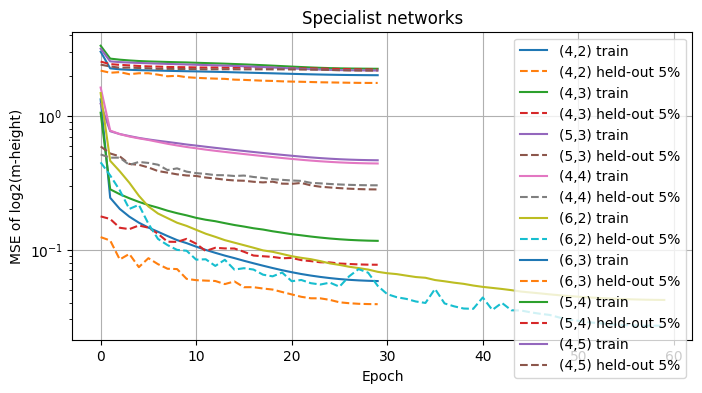

In [12]:
# 7c. Choose, for each group, the v3 ensemble, the specialist, or their average (lowest validation cost)
EXPERT_GROUPS = list(AUG_SETTINGS.keys())
routing = {}
z_val_final = z_val_main.copy()
for k, m in EXPERT_GROUPS:
    sel = np.where((val_k == k) & (val_m == m))[0]
    expert = keras.models.load_model(EXPERT_PATH.format(k, m), safe_mode=False)
    z_exp = expert.predict(x_val[sel, 3:3 + k * (9 - k)], batch_size=4096, verbose=0).reshape(-1).astype(np.float64)
    options = {'v3 ensemble': z_val_main[sel], 'specialist': z_exp, 'average': (z_val_main[sel] + z_exp) / 2}
    costs = {name: np.mean((np.clip(z, 0.0, 60.0) - z_val[sel]) ** 2) for name, z in options.items()}
    best = min(costs, key=costs.get)
    print(f'({k},{m}) on {len(sel)} validation samples: ' + '  '.join(f'{n} {c:.4f}' for n, c in costs.items())
          + f'  -> {best}')
    if best != 'v3 ensemble':
        routing[f'{k},{m}'] = {'mode': 'expert' if best == 'specialist' else 'average',
                               'file': EXPERT_PATH.format(k, m)}
        z_val_final[sel] = options[best]

with open('routing.json', 'w') as f:
    json.dump(routing, f, indent=1)
shutil.copy('routing.json', DRIVE_DIR)
print('\nrouting.json =', routing)
per_km_report(z_val_main, '\nv3 ensemble alone')
per_km_report(z_val_final, 'FINAL (v3 ensemble + specialists)')

if expert_histories:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(8, 4))
    for (k, m), h in expert_histories.items():
        plt.plot(h.history['loss'], label=f'({k},{m}) train')
        plt.plot(h.history['val_loss'], '--', label=f'({k},{m}) held-out 5%')
    plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('MSE of log2(m-height)')
    plt.title('Specialist networks'); plt.grid(True); plt.legend(); plt.show()

### Results (validation cost per `(k, m)`)

| (k, m) | (4,2) | (4,3) | (4,4) | (4,5) | (5,2) | (5,3) | (5,4) | (6,2) | (6,3) | overall |
|---|---|---|---|---|---|---|---|---|---|---|
| ensemble | 0.052 | 0.089 | 0.297 | 2.129 | 0.059 | 0.271 | 2.204 | 0.130 | 1.785 | 0.6093 |
| specialist | 0.040 | 0.077 | 0.312 | 2.176 | 0.035 | 0.292 | 2.222 | 0.029 | 1.836 | — |
| **final** | **0.040** | **0.077** | **0.292** | **2.129** | **0.035** | **0.270** | **2.197** | **0.029** | **1.768** | **0.5944** |
| choice | specialist | specialist | average | ensemble | specialist | average | average | specialist | average | |

In [13]:
# Save the training histories of the specialists trained in the second 7b-3 session (local + Google Drive)
for (k, m), h in expert_histories.items():
    hist_file = EXPERT_PATH.format(k, m) + '.history.json'
    json.dump({key: [float(v) for v in vals] for key, vals in h.history.items()}, open(hist_file, 'w'))
    shutil.copy(hist_file, DRIVE_DIR)
    print('saved', hist_file)

saved expert_k4_m2.keras.history.json
saved expert_k4_m3.keras.history.json
saved expert_k5_m3.keras.history.json
saved expert_k4_m4.keras.history.json
saved expert_k6_m2.keras.history.json
saved expert_k6_m3.keras.history.json
saved expert_k5_m4.keras.history.json
saved expert_k4_m5.keras.history.json


### Training curves of the specialists

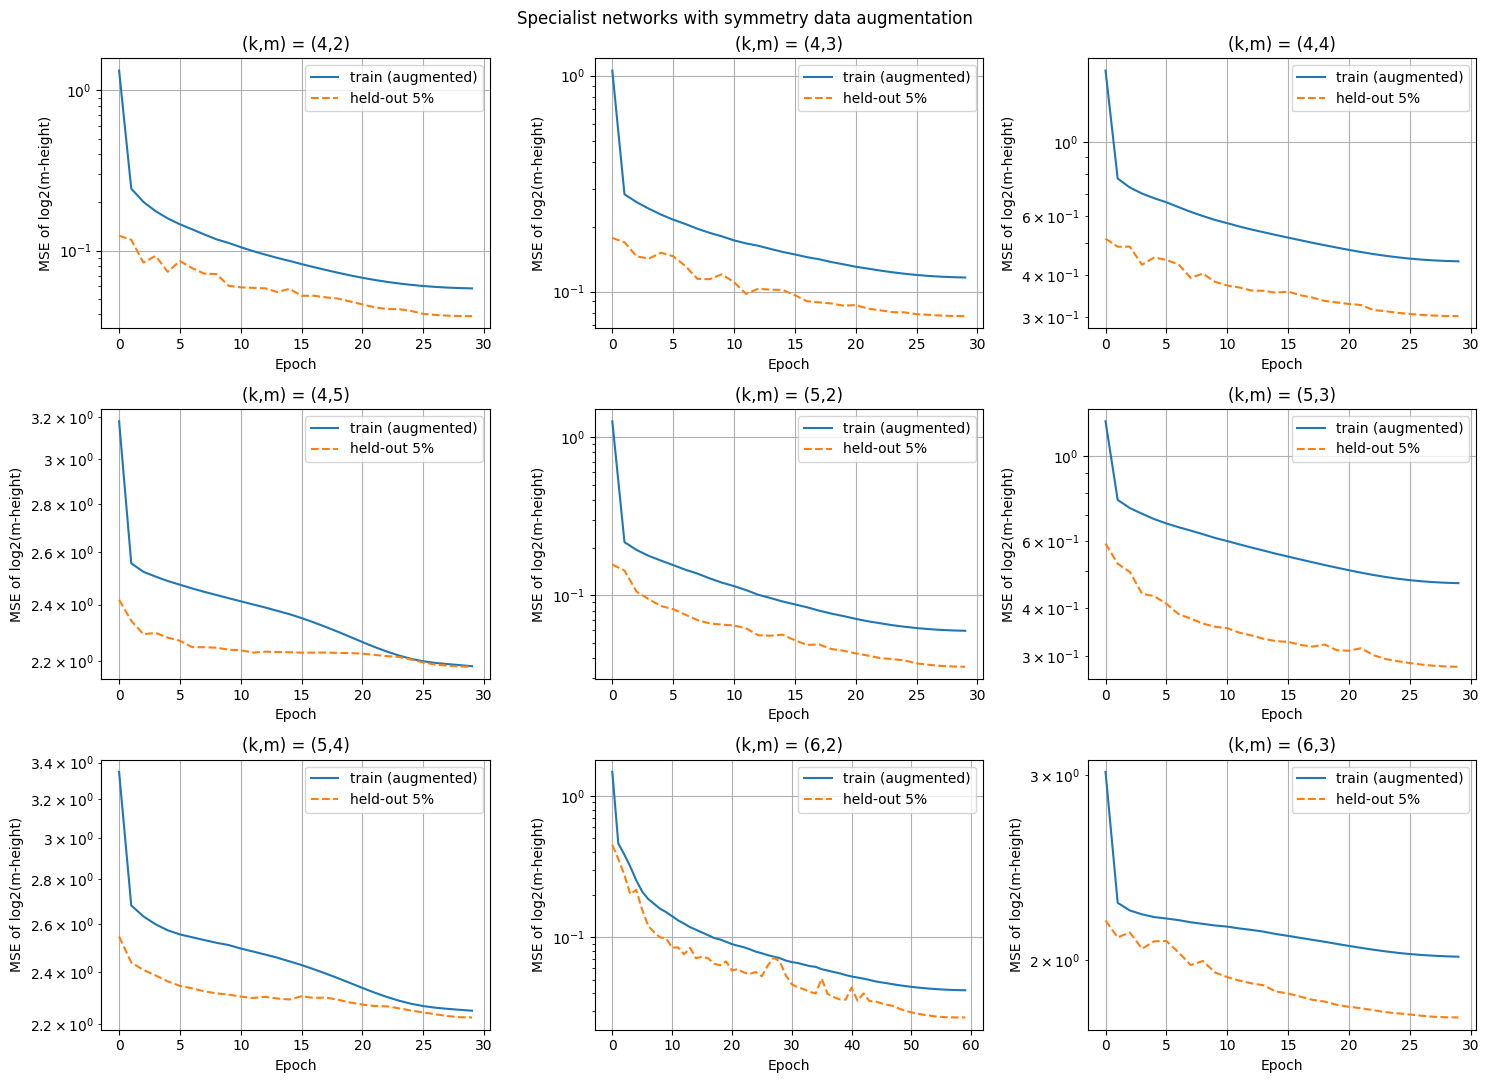

In [14]:
# Training curves of all specialist networks (3 x 3 grid, one panel per (k, m))
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, (k, m) in zip(axes.flat, sorted(AUG_SETTINGS)):
    f = EXPERT_PATH.format(k, m) + '.history.json'
    src = f if os.path.exists(f) else os.path.join(DRIVE_DIR, f)
    if not os.path.exists(src):
        ax.set_title(f'({k},{m}): no history'); continue
    h = json.load(open(src))
    ax.plot(h['loss'], label='train (augmented)')
    ax.plot(h['val_loss'], '--', label='held-out 5%')
    ax.set_yscale('log'); ax.set_title(f'(k,m) = ({k},{m})'); ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE of log2(m-height)'); ax.grid(True); ax.legend()
fig.suptitle('Specialist networks with symmetry data augmentation')
plt.tight_layout(); plt.show()

## 8. Final cell — test the submitted model
This cell loads `best_model.keras`, `routing.json` and the specialist files, and reads a test file in the format of `CSCE-636-Project-1-Train-n_k_m_P`. Every sample is predicted by the ensemble. For the groups listed in `routing.json`, that prediction is replaced by the specialist's, or by the average of the two. The cell writes `CSCE-636-Project-1-Test-mHeights`, a pickled list of floats, each at least 1.

In [ ]:
import pickle, json
import numpy as np
import keras

MODEL_PATH = 'best_model.keras'        # v3 ensemble (all groups)
ROUTING_PATH = 'routing.json'          # which (k, m) groups use a specialist network
TEST_X_PATH = 'CSCE-636-Project-1-Test-n_k_m_P'
OUTPUT_PATH = 'CSCE-636-Project-1-Test-mHeights'

def preprocess_sample_test(sample, max_p_length=20):
    n, k, m, P = sample
    P_flat = np.asarray(P, dtype=np.float64).flatten()
    padded_P = np.pad(P_flat, (0, max_p_length - len(P_flat)), mode='constant')
    return np.concatenate(([n, k, m], padded_P))

with open(TEST_X_PATH, 'rb') as f:
    raw_test_x = pickle.load(f)
X_test = np.array([preprocess_sample_test(s) for s in raw_test_x], dtype=np.float32)
k_arr, m_arr = X_test[:, 1].astype(int), X_test[:, 2].astype(int)

model = keras.models.load_model(MODEL_PATH, safe_mode=False)
z_test_pred = model.predict(X_test, batch_size=4096, verbose=0).reshape(-1).astype(np.float64)

with open(ROUTING_PATH) as f:
    routing = json.load(f)
for key, r in routing.items():
    k, m = map(int, key.split(','))
    idx = np.where((k_arr == k) & (m_arr == m))[0]
    if len(idx) == 0:
        continue
    expert = keras.models.load_model(r['file'], safe_mode=False)
    z_exp = expert.predict(X_test[idx, 3:3 + k * (9 - k)], batch_size=4096, verbose=0).reshape(-1).astype(np.float64)
    z_test_pred[idx] = z_exp if r['mode'] == 'expert' else (z_test_pred[idx] + z_exp) / 2

z_test_pred = np.nan_to_num(z_test_pred, nan=0.0, posinf=60.0, neginf=0.0)   # safety: never NaN / inf
y_test_pred = np.power(2.0, np.clip(z_test_pred, 0.0, 60.0))                # guarantees 1 <= y_hat < infinity
y_test_pred_list = [float(v) for v in y_test_pred]

with open(OUTPUT_PATH, 'wb') as f:
    pickle.dump(y_test_pred_list, f)
assert len(y_test_pred_list) == len(raw_test_x) and all(1.0 <= v < float('inf') for v in y_test_pred_list)
print(f'{len(y_test_pred_list)} predictions saved to {OUTPUT_PATH}; first 5: {y_test_pred_list[:5]}')

2000 predictions saved to CSCE-636-Project-1-Test-mHeights; first 5: [519.6363303307236, 196.05935028329242, 30.476503945328002, 50.86781233779391, 61.01174186637497]
